# CTI K/V resolution: K2 vs K4 (SPFI ×4, EMPS, Colab GPU)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SS1162/SR_amat_3/blob/Tehila_Navon/notebooks/cti_scales_colab.ipynb)

**Question.** In the CTI block (Cross-token Integration, `algo/cti.py`), how small can the K and V
maps be before SPFI's super-resolution quality drops, and how much computation does it save?

**How CTI builds K and V** (for a 64×64 feature map):
1. Three branches, each a depth-wise separable conv: 3×3 / stride 1, 5×5 / stride 2, 7×7 / stride 4.
   Depth-wise: one filter per channel, looks at neighbours without mixing channels.
   Point-wise (1×1): mixes the channels at each position without looking at neighbours.
2. The branches come out at 64×64, 32×32 and 16×16. This is done separately for K and for V (6 maps).
3. To combine them, all branches are resized (bilinear) to one common size, mixed, and fused by a 1×1 conv.

**What changes: K, the common size in step 3.**

| Config | K and V size | K/V tokens per attention | Q tokens |
|---|---|---|---|
| **K2** | 32×32 (H/2) | 1,024 | 4,096 |
| **K4** | 16×16 (H/4) | 256 | 4,096 |

Q keeps the full 64×64 map, so the output keeps full resolution. Smaller K/V means each of the 4,096
queries compares against fewer positions, which is where the computation is saved.

**What stays the same.** Everything else: the three branches, the SPFI model (`algo/model.py`, `algo/sci.py`), loss
(Charbonnier + 0.5·(1−SSIM)), optimizer (AdamW, lr 1e-4), ×4 scale, 64×64 LR patches, the seed,
the initial weights, and the exact order of training patches.

**Protocol.**
* Data: only EMPS's `train.csv` images (366), split 80/20 into training / validation, the same as
  `train_colab.ipynb`. The 99 `test.csv` images are never used.
* Each config trains for the same number of iterations (batch size 1).
* Every `EVAL_EVERY` iterations: PSNR and SSIM on 32 fixed validation patches. The table reports the
  best check and the last check, since the last step alone is noisy.
* Cost: parameters, forward GFLOPs on a 64×64 LR input, and GPU forward time.
* Baseline: plain bicubic upscaling on the same validation patches. A useful model must beat it.

The experiment code is `algo/compare_cti_scales.py`; this notebook only runs it and shows the results.

In [1]:
import torch

print("torch", torch.__version__)
if not torch.cuda.is_available():
    # Stop "Run all" here: on CPU one config takes 6+ hours instead of ~20 minutes.
    raise RuntimeError("No GPU. Runtime > Change runtime type > T4 GPU, reconnect, then Run all again.")
print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130
GPU: NVIDIA L4


## Settings

In [2]:
from pathlib import Path

CODE_REPO_URL = "https://github.com/SS1162/SR_amat_3.git"
CODE_BRANCH = "Tehila_Navon"

EMPS_URL = "https://github.com/by256/emps.git"
EMPS_COMMIT = "dd8f86d714894fd08f3db80041893982ce058dd6"   # same pinned release as train_colab.ipynb

CONFIGS = ["K2", "K4"]     # to run one at a time (e.g. after a disconnect): ["K4"]; earlier results in OUT_DIR are kept
ITERS = 5000               # training iterations per config
EVAL_EVERY = 500           # PSNR / SSIM check interval
SEED = 0

SAVE_TO_DRIVE = True       # keep results.json + log in Google Drive in case Colab disconnects

CODE_DIR = Path("/content/SR_amat_3")
EMPS_DIR = Path("/content/emps")
OUT_DIR = Path("/content/cti_scales_compare")

## Code, data and dependencies

In [3]:
!pip install -q "pytorch_wavelets>=1.3" "PyWavelets>=1.6" "setuptools<81"

import subprocess

def run(*cmd, cwd=None):
    subprocess.run(list(cmd), cwd=cwd, check=True)

if not CODE_DIR.exists():
    run("git", "clone", "-q", "-b", CODE_BRANCH, CODE_REPO_URL, str(CODE_DIR))
else:
    run("git", "pull", "-q", cwd=CODE_DIR)
print("code:", subprocess.run(["git", "log", "-1", "--oneline"], cwd=CODE_DIR,
                              capture_output=True, text=True).stdout.strip())

if not EMPS_DIR.exists():
    run("git", "clone", "-q", EMPS_URL, str(EMPS_DIR))
run("git", "checkout", "-q", EMPS_COMMIT, cwd=EMPS_DIR)
print("EMPS:", EMPS_COMMIT[:10], "|", len(list((EMPS_DIR / "images").glob("*.png"))), "images,",
      sum(1 for l in (EMPS_DIR / "train.csv").read_text().splitlines() if l.strip()), "in train.csv")

code: e1544d8 Notebook: stop Run all when the runtime has no GPU
EMPS: dd8f86d714 | 465 images, 366 in train.csv


In [4]:
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/cti_scales_compare")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("results go to", OUT_DIR)

Mounted at /content/drive
results go to /content/drive/MyDrive/cti_scales_compare


## Run the comparison
About 30 minutes per config on a T4. Progress is printed every 25 iterations and a PSNR / SSIM
check every `EVAL_EVERY`. The full log is also written to `OUT_DIR/log.txt`.

In [5]:
%cd /content/SR_amat_3
configs = " ".join(f'"{c}"' for c in CONFIGS)
# -W ignore hides the harmless pkg_resources warning; -u + tee stream every line as it is printed.
!python -u -W ignore -m algo.compare_cti_scales --emps_dir {EMPS_DIR} --iters {ITERS} --eval_every {EVAL_EVERY} \
    --seed {SEED} --configs {configs} --out_dir {OUT_DIR} 2>&1 | tee {OUT_DIR}/log.txt

/content/SR_amat_3
device=cuda
using EMPS train split only: 366 images (test.csv held out)
bicubic PSNR on 32 val patches: 28.45 dB
K2: K/V 32x32 (input 64x64)  params=2,355,273  GFLOPs=13.27  fwd=82 ms
  [K2] iter 25/5000  loss=0.4057  0.24s/it
  [K2] iter 50/5000  loss=0.4235  0.22s/it
  [K2] iter 75/5000  loss=0.2795  0.22s/it
  [K2] iter 100/5000  loss=0.3326  0.22s/it
  [K2] iter 125/5000  loss=0.2244  0.22s/it
  [K2] iter 150/5000  loss=0.2802  0.22s/it
  [K2] iter 175/5000  loss=0.1000  0.22s/it
  [K2] iter 200/5000  loss=0.2294  0.22s/it
  [K2] iter 225/5000  loss=0.1238  0.22s/it
  [K2] iter 250/5000  loss=0.2588  0.21s/it
  [K2] iter 275/5000  loss=0.1300  0.21s/it
  [K2] iter 300/5000  loss=0.1344  0.21s/it
  [K2] iter 325/5000  loss=0.1781  0.21s/it
  [K2] iter 350/5000  loss=0.0622  0.21s/it
  [K2] iter 375/5000  loss=0.2269  0.21s/it
  [K2] iter 400/5000  loss=0.2030  0.21s/it
  [K2] iter 425/5000  loss=0.1321  0.21s/it
  [K2] iter 450/5000  loss=0.0716  0.21s/it
  [K2] i

## Results

In [6]:
import json
import pandas as pd

res = json.loads((OUT_DIR / "results.json").read_text())
R = res["results"]
bicubic = R["bicubic"]["psnr"]
NAMES = sorted(k for k in R if k != "bicubic")   # every config saved in results.json

rows = []
for name in NAMES:
    r = R[name]
    rows.append({
        "config": name,
        "K/V size": r["kv_size"],
        "params": f"{r['params']:,}",
        "GFLOPs": round(r["gflops"], 2),
        "fwd ms": round(r["latency_ms"]),
        "best PSNR (dB)": round(r["psnr"], 3),
        "best SSIM": round(r["ssim"], 4),
        "best @ iter": r["best_iter"],
        "last PSNR (dB)": round(r["psnr_last"], 3),
        "last SSIM": round(r["ssim_last"], 4),
        "best PSNR - bicubic": round(r["psnr"] - bicubic, 3),
    })
table = pd.DataFrame(rows).set_index("config")
print(f"iters={res['iters']}  seed={res['seed']}  val patches={res['n_val']}  bicubic PSNR={bicubic:.3f} dB")
table

iters=5000  seed=0  val patches=32  bicubic PSNR=28.452 dB


,K/V size,params,GFLOPs,fwd ms,best PSNR (dB),best SSIM,best @ iter,last PSNR (dB),last SSIM,best PSNR - bicubic
config,,,,,,,,,,
K2,32x32,"2,355,273",13.27,82,29.343,0.7941,2500,29.035,0.7692,0.891
K4,16x16,"2,355,273",8.01,74,29.419,0.7963,4000,28.153,0.7154,0.967


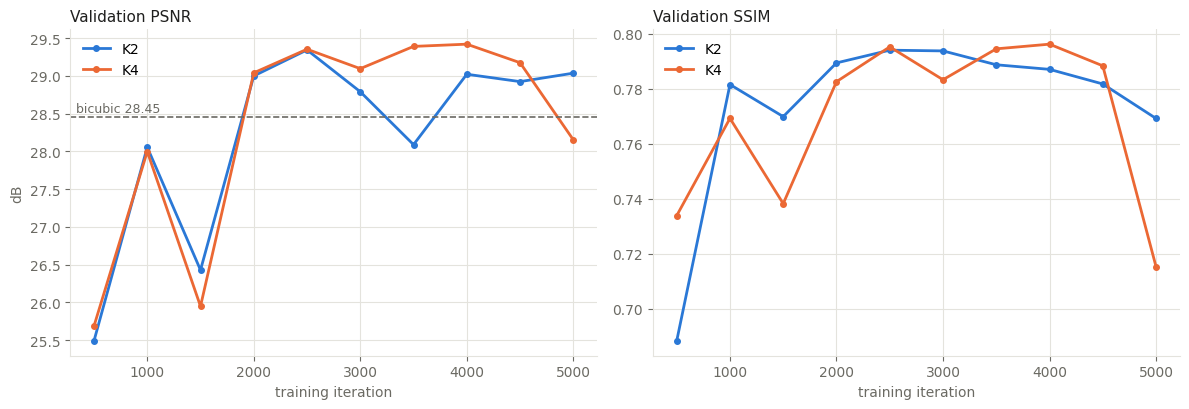

In [7]:
import matplotlib.pyplot as plt

# Color follows the config, never its position in the run (validated categorical slots).
COLORS = {"K2": "#2a78d6", "K4": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3dd"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, key, title, unit in [(axes[0], "psnr", "Validation PSNR", "dB"),
                             (axes[1], "ssim", "Validation SSIM", "")]:
    for name in NAMES:
        h = R[name]["history"]
        x = [p["iter"] for p in h]
        y = [p[key] for p in h]
        ax.plot(x, y, color=COLORS.get(name), linewidth=2, marker="o", markersize=4, label=name)
    if key == "psnr":
        ax.axhline(bicubic, color=MUTED, linewidth=1.2, linestyle="--")
        ax.annotate(f"bicubic {bicubic:.2f}", (0, bicubic), xytext=(4, 4), textcoords="offset points",
                    xycoords=("axes fraction", "data"), color=MUTED, fontsize=9)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("training iteration", color=MUTED)
    ax.set_ylabel(unit, color=MUTED)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUT_DIR / "curves.png", dpi=150)
plt.show()

In [8]:
# Every check, as a table (same numbers as the plot).
pd.DataFrame({
    (name, key): {p["iter"]: round(p[key], 4) for p in R[name]["history"]}
    for name in NAMES for key in ("psnr", "ssim")
})

K2               K4        
         psnr    ssim     psnr    ssim
500   25.4898  0.6884  25.6865  0.7339
1000  28.0548  0.7816  27.9973  0.7693
1500  26.4278  0.7699  25.9480  0.7383
2000  28.9985  0.7895  29.0398  0.7826
2500  29.3433  0.7941  29.3524  0.7953
3000  28.7894  0.7938  29.0953  0.7833
3500  28.0888  0.7888  29.3898  0.7946
4000  29.0211  0.7871  29.4194  0.7963
4500  28.9235  0.7818  29.1739  0.7884
5000  29.0355  0.7692  28.1530  0.7154

## Conclusion

**Quality: K4 matches K2.** K4 has the higher PSNR at 7 of 10 checks. Averaged over iterations 2500–5000
it scores 29.10 dB vs 28.87 dB for K2 (+0.23 dB); SSIM over 2500–4500 is 0.792 vs 0.789. This gap is
smaller than the run-to-run noise (the same K2 config, same seed, differed by up to 0.8 dB at single
checks between two runs, one on a T4 and one on an L4), so the two are equal in quality within what this experiment can measure.

**vs bicubic:** both beat bicubic (28.45 dB) by about 0.5–1 dB from iteration 2000 on; K4 stays above it
at every check from 2000 to 4500.

**Cost:** same parameter count (2,355,273). K4 needs 8.01 GFLOPs vs 13.27 for K2 (−40%) and runs
74 ms vs 82 ms per forward pass on an NVIDIA L4. For reference, the original CTI (K/V at full 64×64) needs 34.31 GFLOPs.

**Recommendation: K4.** Same quality as K2 at 40% less computation.

The last check (iteration 5000) drops for both configs, K4 more (28.15 dB / 0.715 SSIM). It is a
single-step spike from training with batch size 1 and a constant learning rate, which is why the
comparison uses every check rather than the last one.

**Limits of this experiment:** one seed, batch size 1, a short fixed budget (5000 iterations, not trained
to convergence), validation on 32 patches from the train split. The test split is untouched and is for
the final model evaluation (`inference_colab.ipynb`). To confirm, repeat with `SEED = 1` or train longer.
